# 07 · Explicabilidad (SHAP) y política de aprobación

1. **¿Por qué el campeón decide lo que decide?** SHAP global y por préstamo.
2. **¿A quién aprobar?** Política por **utilidad esperada** contra un corte único de PD.

SHAP se calcula con el **TreeSHAP nativo de LightGBM** (`pred_contrib=True`): exacto y sin dependencias extra. Código en `src/credit_lab/explicar.py` y `src/credit_lab/politica.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from credit_lab.campeon import cargar
from credit_lab.poblacion import cargar_poblacion
from credit_lab.features import derivar
from credit_lab.explicar import contribuciones, explicar_prestamo, NOMBRES
from credit_lab.negocio import utilidad_prestamo
from credit_lab.politica import rendimientos_por_subgrado, utilidad_esperada, aprobar

pd.set_option("display.float_format", "{:,.4f}".format)
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

campeon = cargar()
df = cargar_poblacion()
oot = df[df["muestra"].eq("oot")]
s1, s2 = oot[oot["issue_d"].dt.month <= 6], oot[oot["issue_d"].dt.month > 6]

## 1. SHAP global: ¿qué variables pesan más?

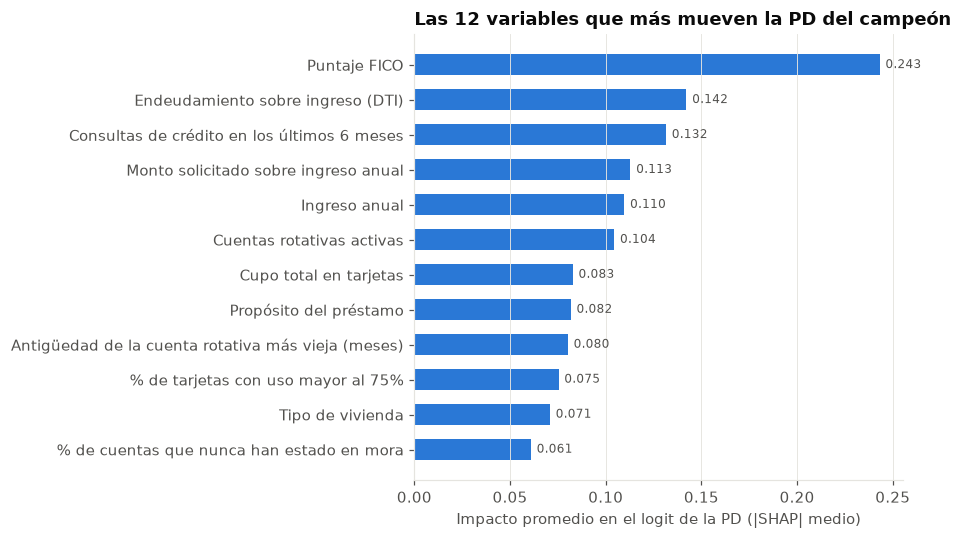

In [2]:
muestra = oot.sample(20_000, random_state=0)
shap = contribuciones(campeon, muestra)
assert np.allclose(shap.sum(axis=1), np.log(campeon.pd(muestra) / (1 - campeon.pd(muestra))))  # suma exacta

imp = shap.drop(columns="valor_base").abs().mean().sort_values(ascending=False)
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh([NOMBRES.get(v, v) for v in top.index], top.values, color=AZUL, height=0.6)
for i, v in enumerate(top.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8, color=TINTA_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Impacto promedio en el logit de la PD (|SHAP| medio)")
ax.set_title("Las 12 variables que más mueven la PD del campeón")
fig.tight_layout()

### Dirección del efecto

Cada punto es un préstamo: a la derecha sube el riesgo, a la izquierda lo baja. El color es el valor de la variable (claro = bajo, oscuro = alto).

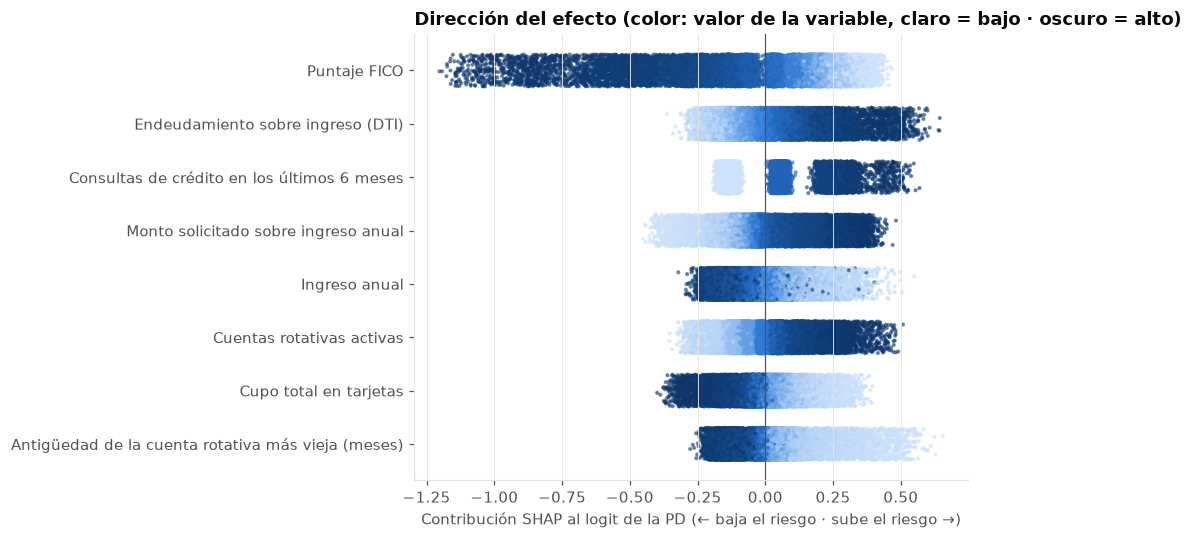

In [3]:
datos = derivar(muestra)
azules = LinearSegmentedColormap.from_list("azules", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
vars_num = [v for v in imp.index if pd.api.types.is_numeric_dtype(datos[v])][:8][::-1]
fig, ax = plt.subplots(figsize=(9, 5))
rng = np.random.default_rng(0)
for i, v in enumerate(vars_num):
    color = datos[v].rank(pct=True).fillna(0.5)
    ax.scatter(shap[v], i + rng.uniform(-0.3, 0.3, len(shap)), c=color, cmap=azules, s=3, alpha=0.5)
ax.axvline(0, color=TINTA_2, linewidth=0.8)
ax.set_yticks(range(len(vars_num)), [NOMBRES.get(v, v) for v in vars_num])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Contribución SHAP al logit de la PD (← baja el riesgo · sube el riesgo →)")
ax.set_title("Dirección del efecto (color: valor de la variable, claro = bajo · oscuro = alto)")
fig.tight_layout()

## 2. SHAP por préstamo: ¿por qué este cliente sacó esta PD?

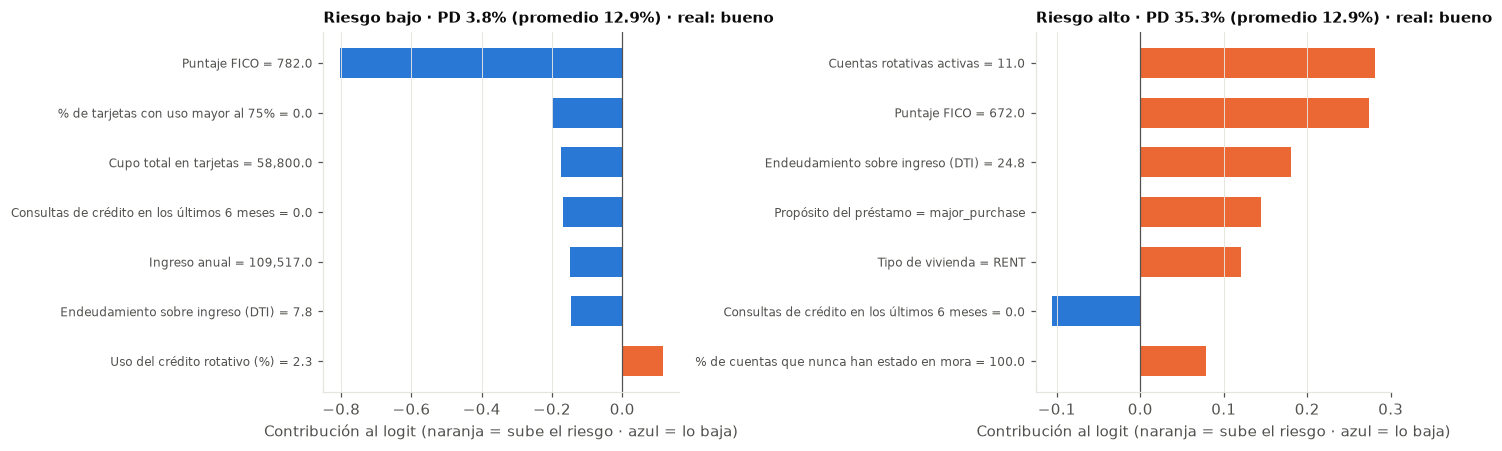

In [4]:
pd_s2 = campeon.pd(s2)
ejemplos = {"Riesgo bajo": s2.index[np.argsort(pd_s2)[len(s2) // 20]],
            "Riesgo alto": s2.index[np.argsort(pd_s2)[-len(s2) // 50]]}

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (titulo, idx) in zip(ejes, ejemplos.items()):
    e = explicar_prestamo(campeon, s2.loc[[idx]], top=7)
    razones = pd.DataFrame(e["razones"]).iloc[::-1]
    etiquetas = [f"{r.descripcion} = {r.valor:,.1f}" if isinstance(r.valor, (int, float, np.floating)) else f"{r.descripcion} = {r.valor}"
                 for r in razones.itertuples()]
    colores = [NARANJA if v > 0 else AZUL for v in razones["contribucion_logit"]]
    ax.barh(etiquetas, razones["contribucion_logit"], color=colores, height=0.6)
    ax.axvline(0, color=TINTA_2, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_title(f"{titulo} · PD {e['pd']:.1%} (promedio {e['pd_base']:.1%}) · real: {'malo' if s2.loc[idx, 'malo'] else 'bueno'}", fontsize=10)
    ax.set_xlabel("Contribución al logit (naranja = sube el riesgo · azul = lo baja)")
fig.tight_layout()

## 3. Política de aprobación: ¿corte de PD o utilidad esperada?

La sesión 6 mostró que **más AUC no es más plata**. La razón: un préstamo bueno rinde según su tasa, pero uno malo pierde ~36% del monto en cualquier subgrado (flujos reales, entrenamiento 2012–2014).

In [5]:
rend = rendimientos_por_subgrado(df[df["muestra"].eq("train")])
rend.iloc[::5]

,r_bueno,r_malo,pd_equilibrio
sub_grade,,,
A1,0.0788,-0.3700,0.1755
B1,0.1279,-0.3594,0.2625
C1,0.1800,-0.3550,0.3364
D1,0.2229,-0.3648,0.3792
E1,0.2599,-0.3555,0.4224
F1,0.3165,-0.3478,0.4764
G1,0.3139,-0.3685,0.4600


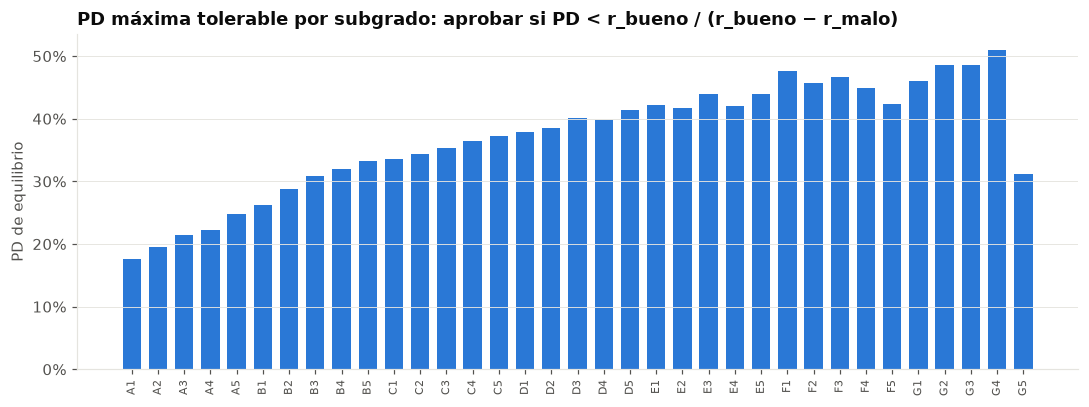

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(rend))
ax.bar(x, rend["pd_equilibrio"], color=AZUL, width=0.7)
ax.set_xticks(x, rend.index, rotation=90, fontsize=7)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", visible=False)
ax.set_ylabel("PD de equilibrio")
ax.set_title("PD máxima tolerable por subgrado: aprobar si PD < r_bueno / (r_bueno − r_malo)")
fig.tight_layout()

**Política por utilidad esperada:**

    utilidad_esperada = monto × [(1 − PD) × r_bueno + PD × r_malo]   → aprobar si > 0

Usa la **PD recalibrada** del campeón: aquí el **nivel** de la PD sí importa (decisión 007).

### Comparación justa

El corte de PD y el margen se **eligen con el 1er semestre de 2015** y se **evalúan en el 2º**. Elegir el corte mirando el mismo periodo en que se evalúa infla el resultado (en una primera prueba daba +USD 1,9 M; en la prueba justa, +USD 0,7 M).

In [7]:
p1, p2 = campeon.pd(s1), pd_s2
u1, u2 = utilidad_prestamo(s1).to_numpy(), utilidad_prestamo(s2).to_numpy()
m2, y2 = s2["funded_amnt"].to_numpy(), s2["malo"].to_numpy()

umbral = max(np.quantile(p1, np.arange(0.5, 1.0, 0.005)), key=lambda t: u1[p1 <= t].sum())
margen = max(np.arange(-0.04, 0.0801, 0.005), key=lambda mg: u1[aprobar(s1, p1, rend, mg)].sum())

def resultado(ap):
    return {"aprobación": ap.mean(), "utilidad_M": u2[ap].sum() / 1e6,
            "vs_aprobar_todo_M": (u2[ap].sum() - u2.sum()) / 1e6,
            "roi": u2[ap].sum() / m2[ap].sum(), "mora_aprobados": y2[ap].mean()}

politicas = pd.DataFrame({
    "Aprobar todo": resultado(np.ones(len(s2), bool)),
    f"Corte único de PD (≤ {umbral:.1%}, elegido en S1)": resultado(p2 <= umbral),
    "Utilidad esperada, margen 0": resultado(aprobar(s2, p2, rend, 0.0)),
    f"Utilidad esperada, margen {margen:.1%} (elegido en S1)": resultado(aprobar(s2, p2, rend, margen)),
}).T
politicas

,aprobación,utilidad_M,vs_aprobar_todo_M,roi,mora_aprobados
Aprobar todo,1.0000,128.1916,0.0000,0.0616,0.1471
"Corte único de PD (≤ 42.4%, elegido en S1)",0.9957,128.8503,0.6587,0.0622,0.1457
"Utilidad esperada, margen 0",0.9824,128.8400,0.6484,0.0630,0.1439
"Utilidad esperada, margen -1.5% (elegido en S1)",0.9912,128.8060,0.6144,0.0625,0.1452


In [8]:
grado = s2["sub_grade"].str[0].to_numpy()
pd.DataFrame({
    "Corte de PD": pd.Series(p2 > umbral).groupby(grado).mean(),
    "Utilidad esperada": pd.Series(~aprobar(s2, p2, rend, 0.0)).groupby(grado).mean(),
}).T.style.format("{:.1%}").set_caption("Tasa de rechazo por grado de Lending Club · 2º semestre 2015")

,A,B,C,D,E,F,G
Corte de PD,0.0%,0.0%,0.4%,1.5%,3.7%,7.2%,12.0%
Utilidad esperada,1.0%,1.3%,2.4%,3.0%,3.7%,4.1%,6.7%


### Lectura honesta

- **Las dos políticas suman lo mismo** (≈ +USD 0,65 M, +0,5% sobre aprobar todo). El precio de Lending Club ya captura casi todo el valor: en esta cartera, el modelo aporta poco en la decisión de **aprobar o rechazar**.
- **La utilidad esperada lo logra con mejor calidad:** mayor ROI (6,30% vs 6,22%) y menor mora en los aprobados (14,4% vs 14,6%), sin necesidad de ajustar ningún parámetro (margen 0 sale de la economía, no de una búsqueda).
- **El corte de PD necesita un umbral extremo (~42%)** encontrado por búsqueda, y concentra el rechazo en los grados F y G.
- **El valor de un mejor modelo aquí estaría en el precio** (cobrar la tasa justa a cada cliente), más que en el rechazo.

---
## ✍️ Conclusiones de Neider

1. El campeón decide con lógica de riesgo: FICO es por lejos lo más importante, seguido de DTI, consultas recientes, monto sobre ingreso e ingreso. Todas las direcciones tienen sentido, y SHAP me da las razones de cada préstamo para explicarlo ante un comité.
2. El IV no es la última palabra: las consultas en 6 meses tenían IV débil (0,0198), pero son la 3ª variable del campeón porque los árboles las aprovechan combinadas con otras. Por eso dejé todas las variables limpias en los árboles (decisión 002).
3. La PD tolerable depende del precio: un A1 aguanta ~18% y un G ~48%, porque el bueno rinde según su tasa y el malo pierde ~36% siempre. Apruebo por utilidad esperada: misma utilidad que el corte de PD, con mejor ROI y menos mora.
4. En esta cartera el precio de Lending Club ya captura casi todo el valor; un mejor modelo aporta más en ponerle la tasa justa a cada cliente que en rechazar. Y elegir un corte mirando el mismo periodo que se evalúa infla el resultado: hay que elegir con un periodo y probar con otro.